# ClinicSense – Notebook 02: Data Preprocessing & Feature Engineering
**B.Sc. Data Science Honours | Student: Kadam Akanksha Dinkar**

This notebook covers:
- Phase 4: Data Preprocessing and Feature Engineering
---

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
import warnings
warnings.filterwarnings('ignore')

from src.data_loader import load_raw
from src.preprocessing import preprocess, stratified_split, temporal_split
from src.feature_engineering import engineer_features, MODEL_FEATURES, add_lead_time
from src.config import FIGURES_DIR, TARGET

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')
print('Setup complete.')

Setup complete.


## 1. Load and Clean Data

In [2]:
# Load raw
df_raw = load_raw()
print(f'Raw shape: {df_raw.shape}')

# Preprocessing
df_proc = preprocess(df_raw)
print(f'After preprocessing: {df_proc.shape}')
df_proc.head()

[DataLoader] Removed 38568 invalid records (110527 → 71959).
Raw shape: (71959, 14)
After preprocessing: (71959, 14)


,patient_id,appointment_id,gender,scheduled_day,appointment_day,age,scholarship,hypertension,diabetes,alcoholism,handicap,sms_received,no_show,neighbourhood_freq
0,9.598513e+13,5626772,0,2016-04-27 08:36:51,2016-04-29,76,0,1,0,0,0,0,0,0.008227
1,7.336882e+14,5630279,0,2016-04-27 15:05:12,2016-04-29,23,0,0,0,0,0,0,1,0.007407
2,3.449833e+12,5630575,0,2016-04-27 15:39:58,2016-04-29,39,0,0,0,0,0,0,1,0.007407
3,7.812456e+13,5629123,0,2016-04-27 12:48:25,2016-04-29,19,0,0,0,0,0,0,0,0.006559
4,7.345362e+14,5630213,0,2016-04-27 14:58:11,2016-04-29,30,0,0,0,0,0,0,0,0.016482


## 2. Outlier Analysis – Age and Lead Time

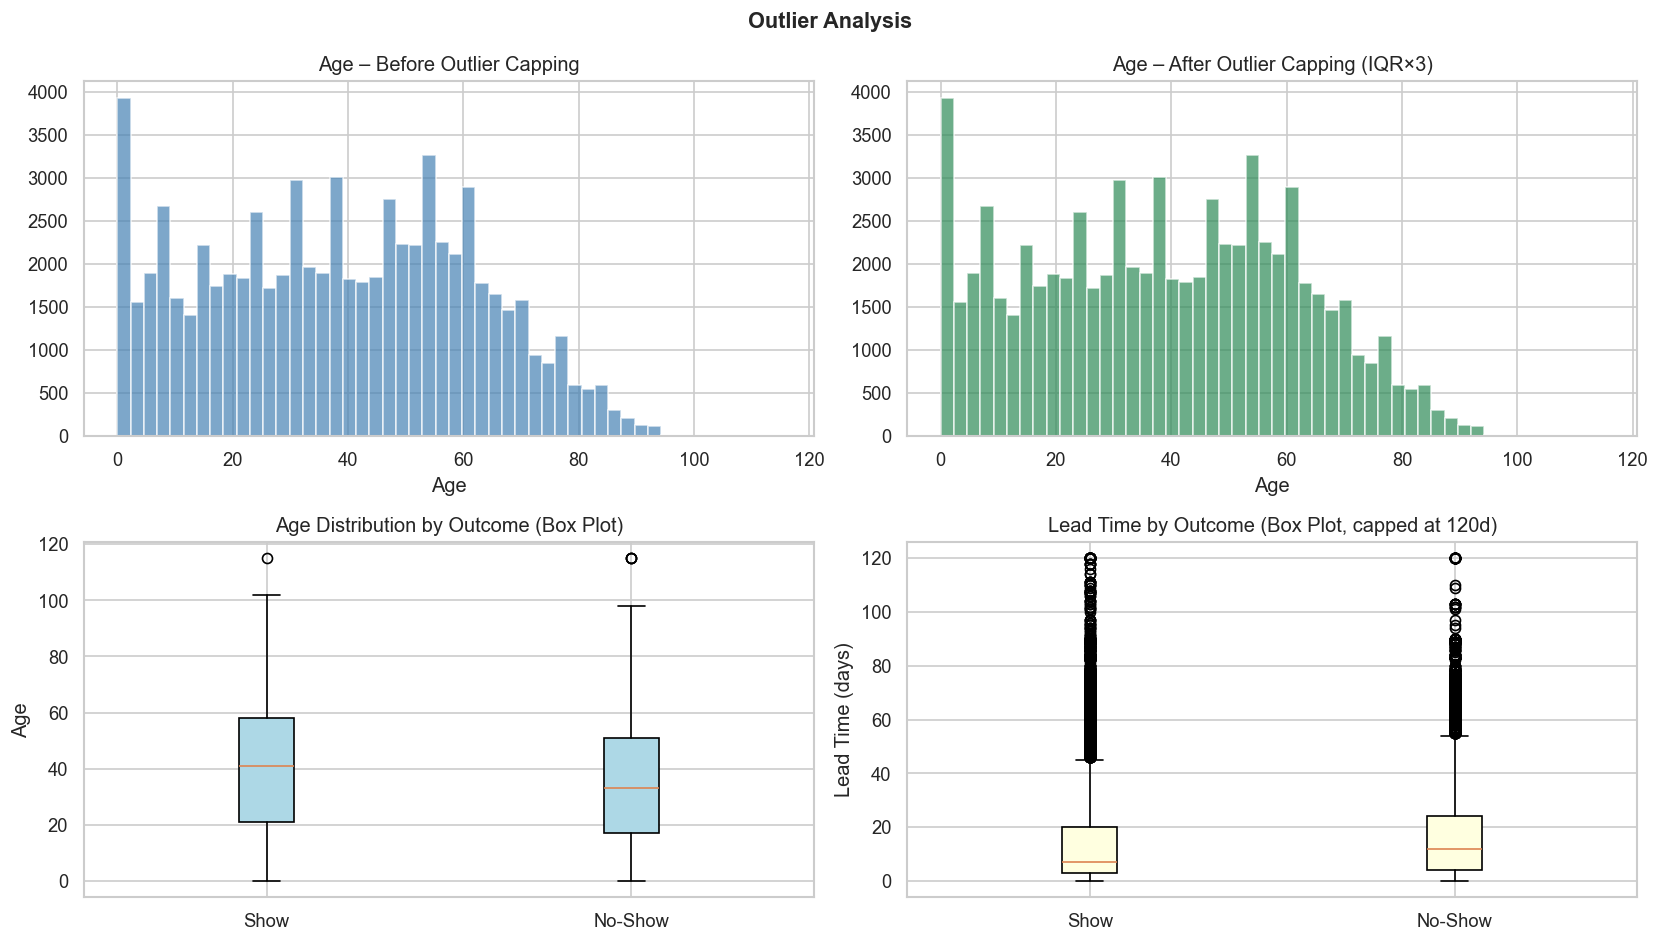

In [3]:
# Compute lead time for analysis
df_proc = add_lead_time(df_proc)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Age before/after capping (from raw to proc)
axes[0,0].hist(df_raw['age'], bins=50, color='steelblue', alpha=0.7)
axes[0,0].set_title('Age – Before Outlier Capping')
axes[0,0].set_xlabel('Age')

axes[0,1].hist(df_proc['age'], bins=50, color='seagreen', alpha=0.7)
axes[0,1].set_title('Age – After Outlier Capping (IQR×3)')
axes[0,1].set_xlabel('Age')

# Box plots
axes[1,0].boxplot([df_proc[df_proc['no_show']==0]['age'],
                   df_proc[df_proc['no_show']==1]['age']],
                  labels=['Show','No-Show'], patch_artist=True,
                  boxprops=dict(facecolor='lightblue'))
axes[1,0].set_title('Age Distribution by Outcome (Box Plot)')
axes[1,0].set_ylabel('Age')

axes[1,1].boxplot([df_proc[df_proc['no_show']==0]['lead_time_days'].clip(upper=120),
                   df_proc[df_proc['no_show']==1]['lead_time_days'].clip(upper=120)],
                  labels=['Show','No-Show'], patch_artist=True,
                  boxprops=dict(facecolor='lightyellow'))
axes[1,1].set_title('Lead Time by Outcome (Box Plot, capped at 120d)')
axes[1,1].set_ylabel('Lead Time (days)')

plt.suptitle('Outlier Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/outlier_analysis.png', dpi=150)
plt.show()

## 3. Feature Engineering

In [4]:
# Apply all feature engineering
df_eng = engineer_features(df_proc)
print(f'Shape after feature engineering: {df_eng.shape}')
print(f'\nNew features added:')
new_cols = [c for c in df_eng.columns if c not in df_proc.columns]
print(new_cols)

df_eng[MODEL_FEATURES + [TARGET]].describe().T

Shape after feature engineering: (71959, 27)

New features added:
['prior_appointments', 'prior_no_shows', 'prior_no_show_rate', 'condition_count', 'same_day_booking']


,count,mean,std,min,25%,50%,75%,max
age,71959.0,38.502564,22.925421,0.000000,19.000000,39.000000,57.000000,115.000000
age_group_enc,71959.0,2.341180,1.321205,0.000000,2.000000,3.000000,3.000000,4.000000
gender,71959.0,0.331981,0.470927,0.000000,0.000000,0.000000,1.000000,1.000000
scholarship,71959.0,0.092706,0.290021,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,71959.0,0.208897,0.406523,0.000000,0.000000,0.000000,0.000000,1.000000
diabetes,71959.0,0.074723,0.262946,0.000000,0.000000,0.000000,0.000000,1.000000
alcoholism,71959.0,0.025320,0.157096,0.000000,0.000000,0.000000,0.000000,1.000000
handicap,71959.0,0.020025,0.154072,0.000000,0.000000,0.000000,0.000000,4.000000
sms_received,71959.0,0.493086,0.499956,0.000000,0.000000,0.000000,1.000000,1.000000
lead_time_days,71959.0,14.642018,16.494334,0.000000,3.000000,8.000000,21.000000,178.000000


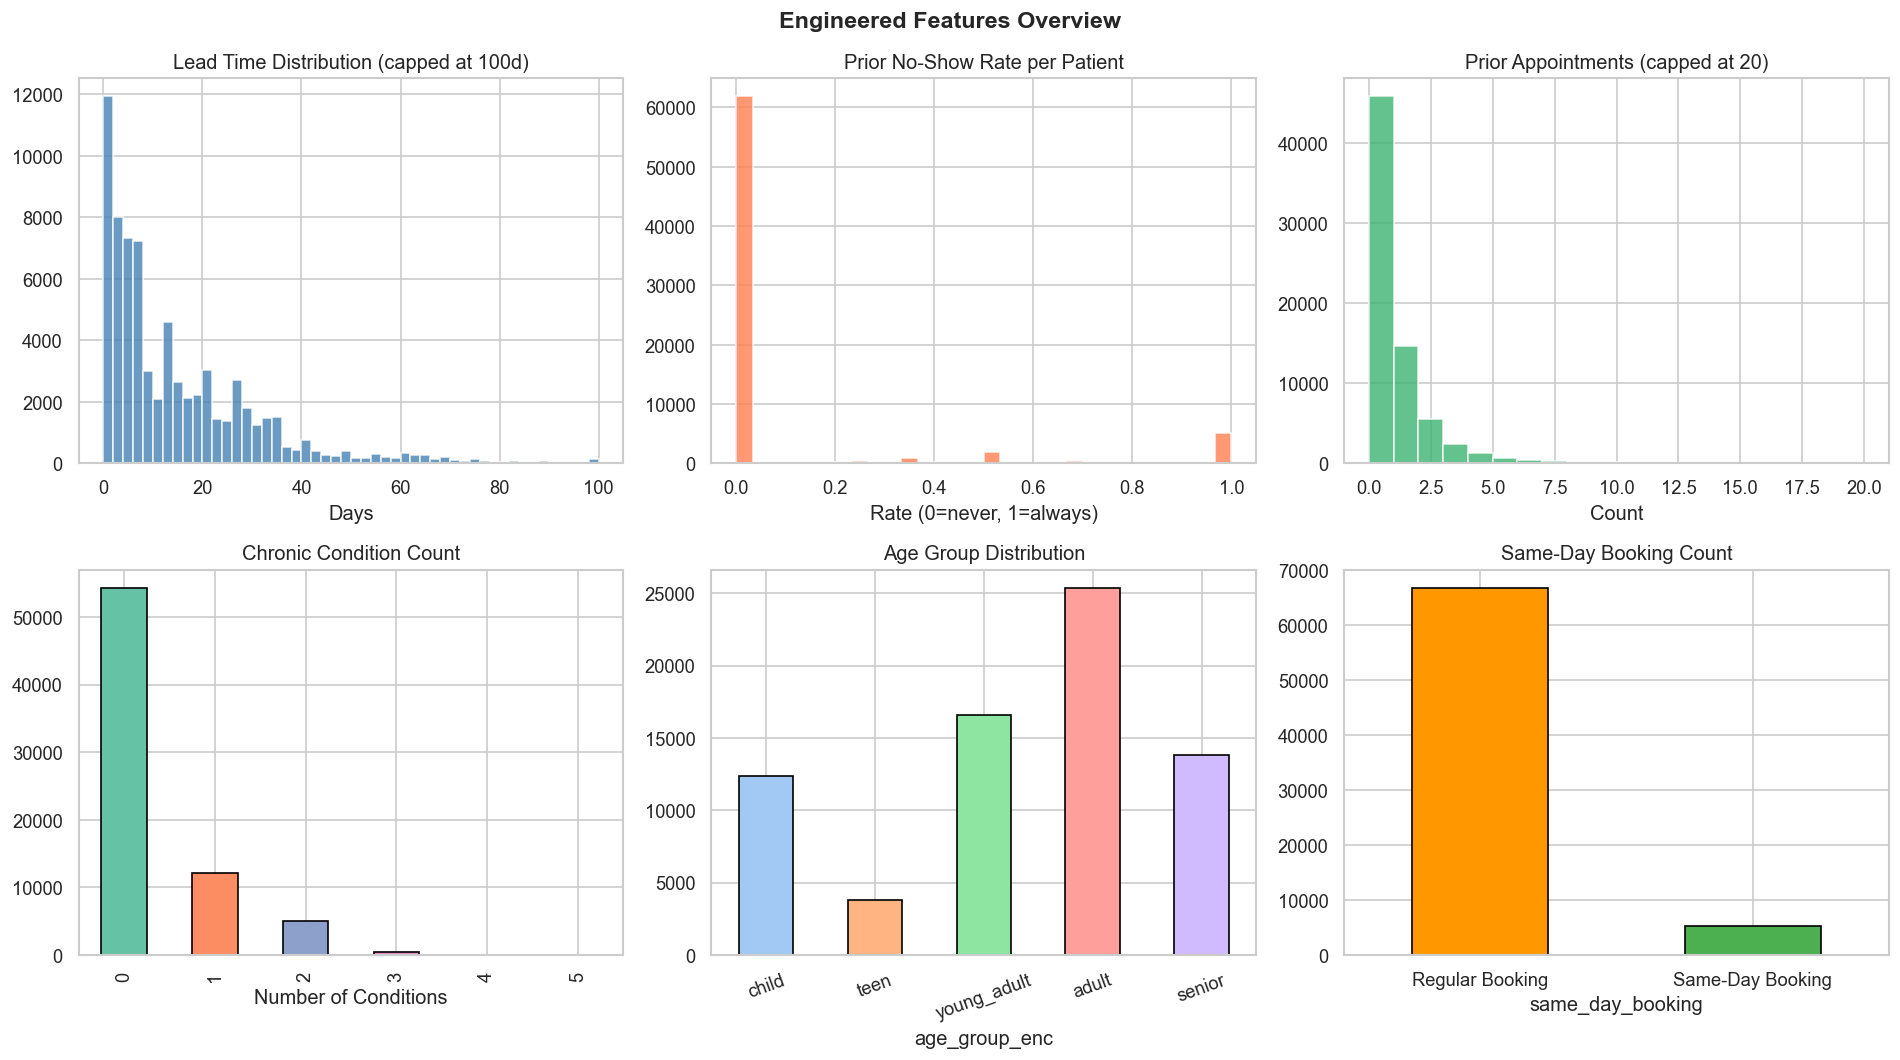

In [5]:
# Visualise engineered features
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Lead time distribution
lead_cap = df_eng['lead_time_days'].clip(upper=100)
axes[0,0].hist(lead_cap, bins=50, color='steelblue', alpha=0.8, edgecolor='white')
axes[0,0].set_title('Lead Time Distribution (capped at 100d)')
axes[0,0].set_xlabel('Days')

# Prior no-show rate distribution
axes[0,1].hist(df_eng['prior_no_show_rate'], bins=30, color='coral', alpha=0.8)
axes[0,1].set_title('Prior No-Show Rate per Patient')
axes[0,1].set_xlabel('Rate (0=never, 1=always)')

# Prior appointments
axes[0,2].hist(df_eng['prior_appointments'].clip(upper=20), bins=20,
               color='mediumseagreen', alpha=0.8)
axes[0,2].set_title('Prior Appointments (capped at 20)')
axes[0,2].set_xlabel('Count')

# Condition count
df_eng['condition_count'].value_counts().sort_index().plot.bar(
    ax=axes[1,0], color=sns.color_palette('Set2', 5), edgecolor='black')
axes[1,0].set_title('Chronic Condition Count')
axes[1,0].set_xlabel('Number of Conditions')

# Age group distribution
age_labels = ['child','teen','young_adult','adult','senior']
df_eng['age_group_enc'].value_counts().sort_index().plot.bar(
    ax=axes[1,1], color=sns.color_palette('pastel', 5), edgecolor='black')
axes[1,1].set_xticklabels(age_labels, rotation=20)
axes[1,1].set_title('Age Group Distribution')

# Same day booking
df_eng['same_day_booking'].value_counts().plot.bar(
    ax=axes[1,2], color=['#FF9800','#4CAF50'], edgecolor='black')
axes[1,2].set_xticklabels(['Regular Booking','Same-Day Booking'], rotation=0)
axes[1,2].set_title('Same-Day Booking Count')

plt.suptitle('Engineered Features Overview', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/engineered_features.png', dpi=150)
plt.show()

## 4. Feature Selection – Mutual Information & Correlation

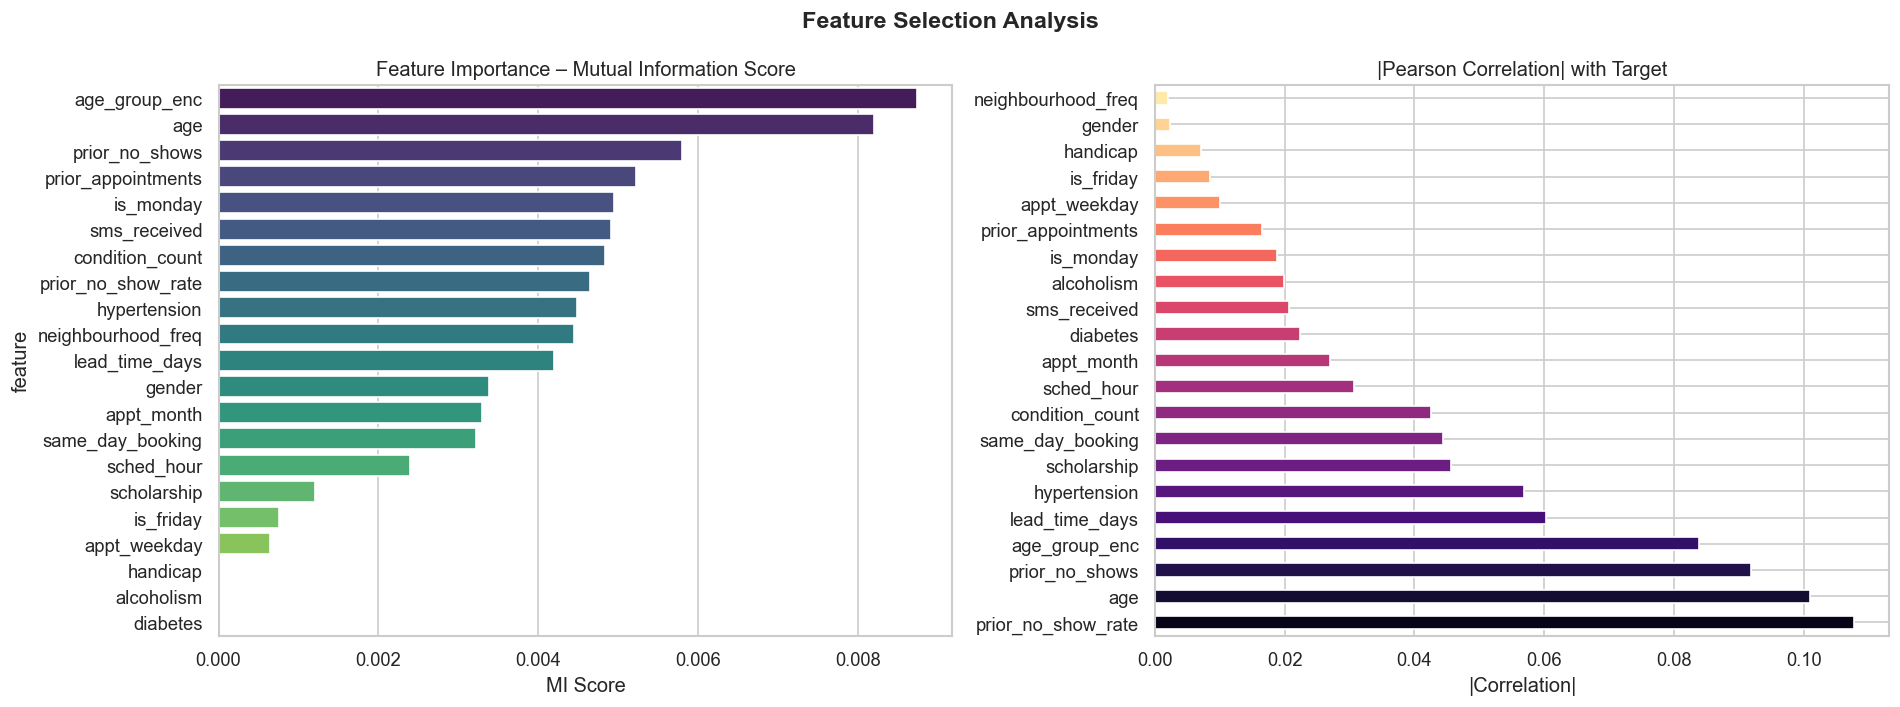

Top 10 features by Mutual Information:
           feature  MI_score
     age_group_enc  0.008743
               age  0.008205
    prior_no_shows  0.005791
prior_appointments  0.005223
         is_monday  0.004951
      sms_received  0.004905
   condition_count  0.004833
prior_no_show_rate  0.004642
      hypertension  0.004480
neighbourhood_freq  0.004442


In [6]:
# Prepare model-ready matrix
available_features = [f for f in MODEL_FEATURES if f in df_eng.columns]
X = df_eng[available_features].fillna(0)
y = df_eng[TARGET]

# Mutual Information
mi_scores = mutual_info_classif(X, y, random_state=42)
mi_df = pd.DataFrame({'feature': available_features, 'MI_score': mi_scores})
mi_df = mi_df.sort_values('MI_score', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=mi_df, x='MI_score', y='feature', palette='viridis',
            orient='h', ax=axes[0])
axes[0].set_title('Feature Importance – Mutual Information Score')
axes[0].set_xlabel('MI Score')

# Correlation with target
target_corr = X.corrwith(y).abs().sort_values(ascending=False)
target_corr.plot.barh(ax=axes[1], color=sns.color_palette('magma', len(target_corr)))
axes[1].set_title('|Pearson Correlation| with Target')
axes[1].set_xlabel('|Correlation|')

plt.suptitle('Feature Selection Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/feature_selection.png', dpi=150)
plt.show()

print('Top 10 features by Mutual Information:')
print(mi_df.head(10).to_string(index=False))

## 5. Multicollinearity Check (VIF)

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)
X_vif = pd.DataFrame(X_scaled, columns=available_features)

vif_data = pd.DataFrame({
    'feature': available_features,
    'VIF': [variance_inflation_factor(X_vif.values, i)
            for i in range(X_vif.shape[1])]
}).sort_values('VIF', ascending=False)

print('Variance Inflation Factor (VIF) – Multicollinearity Check')
print('Rule of thumb: VIF > 10 → high multicollinearity')
print('='*45)
print(vif_data.round(2).to_string(index=False))

high_vif = vif_data[vif_data['VIF'] > 10]
if len(high_vif) > 0:
    print(f'\n⚠ Features with high VIF (>10): {high_vif["feature"].tolist()}')
else:
    print('\n✓ No features with high multicollinearity (VIF ≤ 10 for all).')

Variance Inflation Factor (VIF) – Multicollinearity Check
Rule of thumb: VIF > 10 → high multicollinearity
           feature   VIF
          handicap   inf
   condition_count   inf
      hypertension   inf
          diabetes   inf
        alcoholism   inf
               age 10.06
     age_group_enc  9.33
      appt_weekday  5.05
    prior_no_shows  3.69
         is_friday  2.81
         is_monday  2.65
prior_no_show_rate  2.63
prior_appointments  1.78
      sms_received  1.19
    lead_time_days  1.17
  same_day_booking  1.17
        appt_month  1.11
neighbourhood_freq  1.10
            gender  1.06
       scholarship  1.04
        sched_hour  1.02

⚠ Features with high VIF (>10): ['handicap', 'condition_count', 'hypertension', 'diabetes', 'alcoholism', 'age']


## 6. Train/Test Split and SMOTE

In [8]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print(f'Train size : {len(X_train):,} (no-show rate: {y_train.mean():.3f})')
print(f'Test size  : {len(X_test):,}  (no-show rate: {y_test.mean():.3f})')

# SMOTE oversampling on training set
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f'\nAfter SMOTE:')
print(f'  Train size  : {len(X_train_smote):,}')
print(f'  Class balance: {pd.Series(y_train_smote).value_counts().to_dict()}')

# Save processed data
import os
data_out = os.path.join('..', 'data')
df_eng.to_csv(os.path.join(data_out, 'processed_data.csv'), index=False)
print('\nProcessed data saved to data/processed_data.csv')

# Save splits for next notebooks
import joblib
joblib.dump((X_train, X_test, y_train, y_test),
            os.path.join(data_out, 'splits.joblib'))
joblib.dump((X_train_smote, y_train_smote),
            os.path.join(data_out, 'smote_splits.joblib'))
print('Train/test splits saved to data/splits.joblib')

Train size : 57,567 (no-show rate: 0.285)
Test size  : 14,392  (no-show rate: 0.285)


  File "C:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 966, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1435, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,



After SMOTE:
  Train size  : 82,298
  Class balance: {1: 41149, 0: 41149}



Processed data saved to data/processed_data.csv
Train/test splits saved to data/splits.joblib


## 7. Summary

**Preprocessing steps completed:**
- Fixed column names and data types
- Removed invalid records (negative ages, appointment-before-schedule, duplicates)
- Encoded categorical variables (gender → binary, neighbourhood → frequency encoding)
- Capped outliers using IQR×3 method

**Feature engineering added:**
- Lead time (days between booking and visit)
- Age group (ordinal encoding)
- Weekday and month indicators
- Patient history (prior appointments, prior no-shows, prior no-show rate)
- Condition count
- Same-day booking flag

**Class imbalance handled with SMOTE** on training data only.
**VIF analysis** confirms no severe multicollinearity in the feature set.